# 11 · Mock coding test A — regression, then multi-class classification

**Rules — treat this as the real thing.**

- **150 minutes**, timer running, one sitting.
- A fresh Jupyter session, **no autocomplete, no internet, no AI, no other notebooks from this folder**. What you *may* use (as in the real test): your own homework solution, the official course materials, and library documentation.
- The offline documentation is always one cell away: `help(nn.CrossEntropyLoss)`, `nn.Linear?`, `np.nanmedian?`. Practise using it now — it is the only "tool" you will have.
- Write your solutions between the `# implement your solution BELOW` / `ABOVE` lines. Each sub-task ends with a `tester.test(...)` call that prints `OK` or `FAILED` with a reason. As in the homework, `OK` means *possibly* correct.
- Vectorised solutions are expected; Python loops only for parsing text, for epochs/batches, and for a handful of printed examples or plot annotations.

When the time is up: stop, note which sub-tasks were unfinished and **what exactly held you up**, then compare with the solution notebook.

---
**The data.** `bikes.csv` — hourly records of a bike-rental station. Fields are separated by **semicolons**; the first line holds the names:

`hour;temp_c;humidity;wind_kmh;weekday;season;holiday;rentals`

- `hour` 0–23, `weekday` 0 (Monday) – 6 (Sunday), `holiday` 0/1
- `season` is text: `winter`, `spring`, `summer`, `autumn`
- `temp_c`, `humidity`, `wind_kmh` are sensor readings and **are sometimes missing** (nothing between the semicolons)
- `rentals` — number of bikes rented in that hour: this is what we want to predict

In [1]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

import sys; sys.path.insert(0, "..")
from dnd_utils import TesterA

tester = TesterA()
content = tester.get_dataset_content()
print("Number of characters:", len(content))
print(content[:300])

Number of characters: 57301
hour;temp_c;humidity;wind_kmh;weekday;season;holiday;rentals
20;0.2;89;18.3;2;winter;0;24
20;5.2;88;7.7;2;winter;1;16
6;5.3;80;24.4;4;winter;0;31
0;-2.1;82;18.6;4;winter;0;2
18;8.5;76;5.0;1;winter;0;127
1;0.0;77;19.4;6;winter;0;3
22;-3.1;99;11.3;2;winter;0;5
13;2.2;100;17.0;5;winter;0;58
15;7.1;49;1


## **A** · Loading the dataset

Convert `content` into the NumPy array `dataset_noisy`, shape `(n_samples, 8)`, dtype `np.float32`, columns in file order. `season` becomes the index of the season in the order `winter, spring, summer, autumn` (0–3). Missing values become `np.nan`.

In [2]:
# implement your solution BELOW

SEASONS = ["winter", "spring", "summer", "autumn"]
SEASON_COL = 5

lines = content.split("\n")
rows = [line.split(";") for line in lines[1:] if line]          # no header, no empty last line

def convert(col_idx, text):
    if text == "":
        return np.nan
    if col_idx == SEASON_COL:
        return float(SEASONS.index(text))
    return float(text)

dataset_noisy = np.array([[convert(j, v) for j, v in enumerate(row)] for row in rows], dtype=np.float32)
print(dataset_noisy.shape, dataset_noisy.dtype, np.isnan(dataset_noisy).sum(axis=0))

# implement your solution ABOVE

tester.test('dataset_load', dataset_noisy)

(2000, 8) float32 [  0 116  95  57   0   0   0   0]
Tester: dataset_load OK


True

## **B** · Shuffling and splitting

Shuffle the rows with the permutation `np.random.default_rng(42).permutation(n_samples)` and split them 60 % / 20 % / 20 % into `dataset_split_train`, `dataset_split_val`, `dataset_split_test` (sizes of the first two: `int(n_samples * ratio)`).

Before you do: print the mean of `rentals` for the first and the last 400 rows of the unshuffled file. One comment line: why is shuffling necessary here?

In [3]:
# implement your solution BELOW

print("mean rentals, first 400 rows:", dataset_noisy[:400, 7].mean(), " last 400 rows:", dataset_noisy[-400:, 7].mean())
print("seasons in the last 400 rows:", np.unique(dataset_noisy[-400:, 5]))
# The file is ordered by season: without shuffling, the test set would contain only autumn, which the model never saw.

n_samples = dataset_noisy.shape[0]
perm = np.random.default_rng(42).permutation(n_samples)
shuffled = dataset_noisy[perm]

n_train = int(n_samples * 0.6)
n_val = int(n_samples * 0.2)
dataset_split_train = shuffled[:n_train]
dataset_split_val = shuffled[n_train:n_train + n_val]
dataset_split_test = shuffled[n_train + n_val:]
print(dataset_split_train.shape, dataset_split_val.shape, dataset_split_test.shape)

# implement your solution ABOVE

tester.test('dataset_split', dataset_split_train, dataset_split_val, dataset_split_test)

mean rentals, first 400 rows: 37.665  last 400 rows: 69.0075
seasons in the last 400 rows: [3.]
(1200, 8) (400, 8) (400, 8)
Tester: dataset_split OK


True

## **C** · Pre-processing

Create the **input** matrices `X_train`, `X_val`, `X_test` (`float32`, 13 columns) with exactly this layout:

| columns | content |
|---|---|
| 0–4 | `hour`, `temp_c`, `humidity`, `wind_kmh`, `weekday` — missing values replaced by the **median of that column in the training split**, then **standardised** with the mean and (population) standard deviation of the training split (computed after the replacement) |
| 5 | `holiday` (unchanged) |
| 6–9 | one-hot encoding of `season` (winter, spring, summer, autumn) |
| 10–12 | three indicator columns for `temp_c`, `humidity`, `wind_kmh`: `1` if the value was present, `0` if it was missing |

`rentals` must **not** be among the inputs. Nothing computed from the validation or test split may be used.

In [4]:
# implement your solution BELOW

NUM_COLS = [0, 1, 2, 3, 4]
MISSING_COLS = [1, 2, 3]

medians = np.nanmedian(dataset_split_train[:, MISSING_COLS], axis=0)          # (3,) -- training split only

def build_inputs(split):
    num = split[:, NUM_COLS].copy()                                           # (n, 5)
    num[:, 1:4] = np.where(np.isnan(num[:, 1:4]), medians, num[:, 1:4])       # columns 1..3 of `num` are temp, humidity, wind
    holiday = split[:, 6, None]                                               # (n, 1)
    season_onehot = (split[:, 5, None] == np.arange(4)[None, :]).astype(np.float32)     # (n, 4)
    present = (~np.isnan(split[:, MISSING_COLS])).astype(np.float32)          # (n, 3): 1 = present
    return num, np.concatenate([holiday, season_onehot, present], axis=1)

num_train, rest_train = build_inputs(dataset_split_train)
mean = num_train.mean(axis=0)                                                 # training statistics, after imputation
std = num_train.std(axis=0)

def finish(split):
    num, rest = build_inputs(split)
    return np.concatenate([(num - mean) / std, rest], axis=1).astype(np.float32)

X_train, X_val, X_test = finish(dataset_split_train), finish(dataset_split_val), finish(dataset_split_test)
print(X_train.shape, X_train.dtype, np.isnan(X_train).sum(), X_train[:, :5].mean(axis=0).round(3), X_val[:, :5].mean(axis=0).round(3))

# implement your solution ABOVE

tester.test('preprocess', X_train, X_val, X_test)

(1200, 13) float32 0 [-0. -0. -0. -0. -0.] [ 0.01  -0.029  0.01  -0.014  0.143]
Tester: preprocess OK


True

## **D** · Data iterators for the regression task

Label: `rentals` (column 7). Create the iterables `dataloader_reg_train`, `dataloader_reg_val`, `dataloader_reg_test`. Each step yields two `torch.float32` tensors of shapes `(batch_size, 13)` and `(batch_size, 1)`. Training and validation data are traversed in random order; the test iterator keeps the order of the test split.

In [5]:
# implement your solution BELOW

BATCH_SIZE = 32
LABEL_COL = 7

class RegressionDataset(Dataset):
    def __init__(self, x, y):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.ys = torch.tensor(y, dtype=torch.float32)       # (n,)

    def __len__(self):
        return self.xs.shape[0]

    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx, None]               # (13,), (1,)

yr_train, yr_val, yr_test = dataset_split_train[:, LABEL_COL], dataset_split_val[:, LABEL_COL], dataset_split_test[:, LABEL_COL]

dataloader_reg_train = DataLoader(RegressionDataset(X_train, yr_train), batch_size=BATCH_SIZE, shuffle=True)
dataloader_reg_val = DataLoader(RegressionDataset(X_val, yr_val), batch_size=BATCH_SIZE, shuffle=True)
dataloader_reg_test = DataLoader(RegressionDataset(X_test, yr_test), batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(dataloader_reg_train))
print(xb.shape, xb.dtype, yb.shape, yb.dtype)

# implement your solution ABOVE

tester.test('reg_iter', dataloader_reg_train, dataloader_reg_val, dataloader_reg_test)

torch.Size([32, 13]) torch.float32 torch.Size([32, 1]) torch.float32
Tester: reg_iter OK


True

## **E** · The regression network

Define the network as a subclass of `torch.nn.Module` and assign an instance to `reg_model`: three fully connected layers with **64, 32 and 1** neurons, ReLU between the layers.

In [6]:
# implement your solution BELOW

class RegressionMLP(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),                      # regression: one output, no activation
        )

    def forward(self, x):
        return self.layers(x)

reg_model = RegressionMLP(X_train.shape[1])
print(reg_model(xb).shape, sum(p.numel() for p in reg_model.parameters()))

# implement your solution ABOVE

tester.test('reg_model_architecture', reg_model)

torch.Size([32, 1]) 3009
Tester: reg_model_architecture OK


True

## **F** · Training the regression network

- Train `reg_model` with the **MSE** loss; choose optimizer, learning rate and number of epochs yourself (judge by the validation curve: well trained, not severely over-fitted).
- Measure training and validation loss in every epoch and **plot both on one figure with a legend**; choose the y-range so the end of training is readable.
- Assign the average loss on the **full test set** to `test_mse`.
- Print predicted and true `rentals` for a few test samples.
- In one comment line: what is the MSE of always predicting the training mean, and how does your model compare?

epoch   0   train   8149.2   val   7164.3


epoch  20   train   2047.3   val   1944.0


epoch  40   train   1400.1   val   1362.5


epoch  60   train   1140.4   val   1174.9


epoch  80   train    934.5   val   1103.5


epoch 100   train    808.6   val    984.4


epoch 120   train    688.2   val    923.8


epoch 140   train    599.4   val    817.1


epoch 160   train    523.0   val    831.6


epoch 180   train    478.2   val    832.9


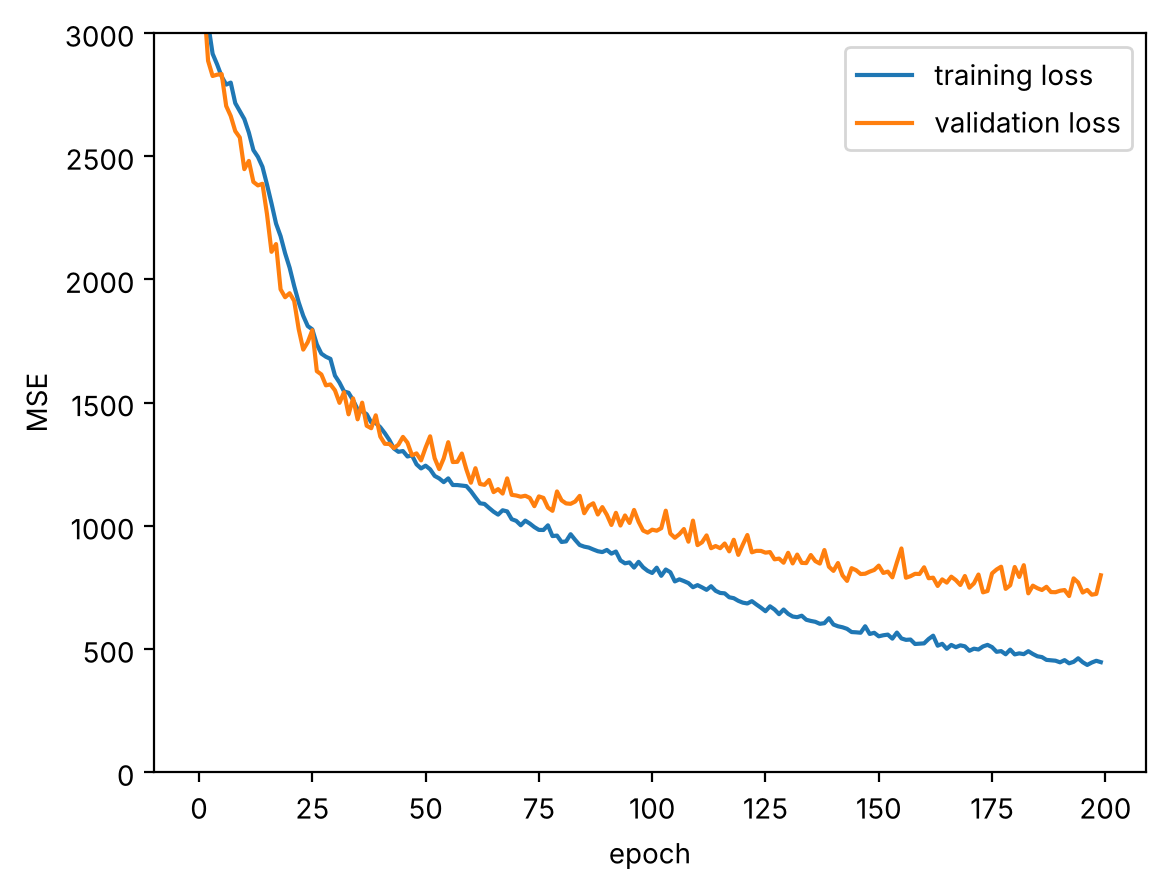

test MSE 813.7   baseline (training mean) 5077.3
predicted  135.8   true  151
predicted  152.0   true  144
predicted  203.7   true  208
predicted   69.9   true   57
predicted  114.8   true   80
predicted  105.0   true   91
predicted   31.9   true   37
predicted   26.1   true    8
Tester: reg_model_learning OK


True

In [7]:
# implement your solution BELOW

torch.manual_seed(0)
reg_model = RegressionMLP(X_train.shape[1])            # fresh model each time the cell runs
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(reg_model.parameters(), lr=0.003)
N_EPOCHS = 200

train_losses, val_losses = [], []
for epoch in range(N_EPOCHS):
    reg_model.train()
    batch_losses = []
    for xb, yb in dataloader_reg_train:
        loss = loss_fn(reg_model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    train_losses.append(np.mean(batch_losses))

    reg_model.eval()
    batch_losses = []
    with torch.no_grad():
        for xb, yb in dataloader_reg_val:
            batch_losses.append(loss_fn(reg_model(xb), yb).item())
    val_losses.append(np.mean(batch_losses))
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d}   train {train_losses[-1]:8.1f}   val {val_losses[-1]:8.1f}")

plt.plot(train_losses, label="training loss")
plt.plot(val_losses, label="validation loss")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.ylim(0, 3000); plt.legend(); plt.show()

reg_model.eval()
preds, trues = [], []
with torch.no_grad():
    for xb, yb in dataloader_reg_test:
        preds.append(reg_model(xb)); trues.append(yb)
preds, trues = torch.cat(preds), torch.cat(trues)
test_mse = loss_fn(preds, trues).item()

baseline_mse = float(((yr_test - yr_train.mean()) ** 2).mean())
print(f"test MSE {test_mse:.1f}   baseline (training mean) {baseline_mse:.1f}")
# The baseline MSE is about 5000 (RMSE ~71 rentals); the network reaches roughly a sixth of that (RMSE ~29).
for p, t in zip(preds[:8, 0], trues[:8, 0]):
    print(f"predicted {p.item():6.1f}   true {t.item():4.0f}")

# implement your solution ABOVE

tester.test('reg_model_learning', test_mse)

## **G** · Data iterators for the classification task

Now we classify the **demand level** of each hour:

- category **0** ("low"): fewer than 25 rentals,
- category **1** ("medium"): at least 25 but fewer than 100,
- category **2** ("high"): 100 or more.

Inputs: the same 13 columns as before. Create `dataloader_cl_train`, `dataloader_cl_val`, `dataloader_cl_test` yielding tensors of shapes `(batch_size, 13)` (`torch.float32`) and `(batch_size,)` (`torch.int64`); random order for training and validation, original order for test. Print the class counts of the three splits.

In [8]:
# implement your solution BELOW

def demand_class(rentals):
    return np.where(rentals < 25, 0, np.where(rentals < 100, 1, 2)).astype(np.int64)

yc_train, yc_val, yc_test = demand_class(yr_train), demand_class(yr_val), demand_class(yr_test)
print(np.bincount(yc_train), np.bincount(yc_val), np.bincount(yc_test))

class ClassificationDataset(Dataset):
    def __init__(self, x, y):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.ys = torch.tensor(y, dtype=torch.int64)

    def __len__(self):
        return self.xs.shape[0]

    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx]                    # scalar label -> (batch,)

dataloader_cl_train = DataLoader(ClassificationDataset(X_train, yc_train), batch_size=BATCH_SIZE, shuffle=True)
dataloader_cl_val = DataLoader(ClassificationDataset(X_val, yc_val), batch_size=BATCH_SIZE, shuffle=True)
dataloader_cl_test = DataLoader(ClassificationDataset(X_test, yc_test), batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(dataloader_cl_train))
print(xb.shape, xb.dtype, yb.shape, yb.dtype)

# implement your solution ABOVE

tester.test('cl_iter', dataloader_cl_train, dataloader_cl_val, dataloader_cl_test)

[436 454 310] [155 140 105] [143 133 124]
torch.Size([32, 13]) torch.float32 torch.Size([32]) torch.int64
Tester: cl_iter OK


True

## **H** · The classification network

A `torch.nn.Module` subclass, instance in `cl_model`: three fully connected layers, the first two with **40 and 20** neurons and ReLU after each, the last one suitable for three-class classification.

In [9]:
# implement your solution BELOW

class ClassificationMLP(nn.Module):
    def __init__(self, n_inputs, n_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, 40), nn.ReLU(),
            nn.Linear(40, 20), nn.ReLU(),
            nn.Linear(20, n_classes),              # raw logits: CrossEntropyLoss applies the softmax itself
        )

    def forward(self, x):
        return self.layers(x)

cl_model = ClassificationMLP(X_train.shape[1], 3)
print(cl_model(xb).shape)

# implement your solution ABOVE

tester.test('cl_model_architecture', cl_model)

torch.Size([32, 3])
Tester: cl_model_architecture OK


True

## **I** · Training the classifier with early stopping

- **Cross-entropy** loss; measure training and validation loss per epoch; plot both with a legend.
- **Early stopping**: stop when the validation loss has not improved for `patience` epochs, and **automatically restore the weights of the best epoch**.
- `test_ce`: average loss on the full test set; `test_acc`: accuracy on the test set.
- Print predicted and true categories for a few test samples.
- Compute the **confusion matrix** of the test set (`[i, j]` = number of samples of true category `i` predicted as `j`) and plot it: both axes labelled, category indices at the ticks, counts inside the cells.

early stopping at epoch 104; best epoch 84


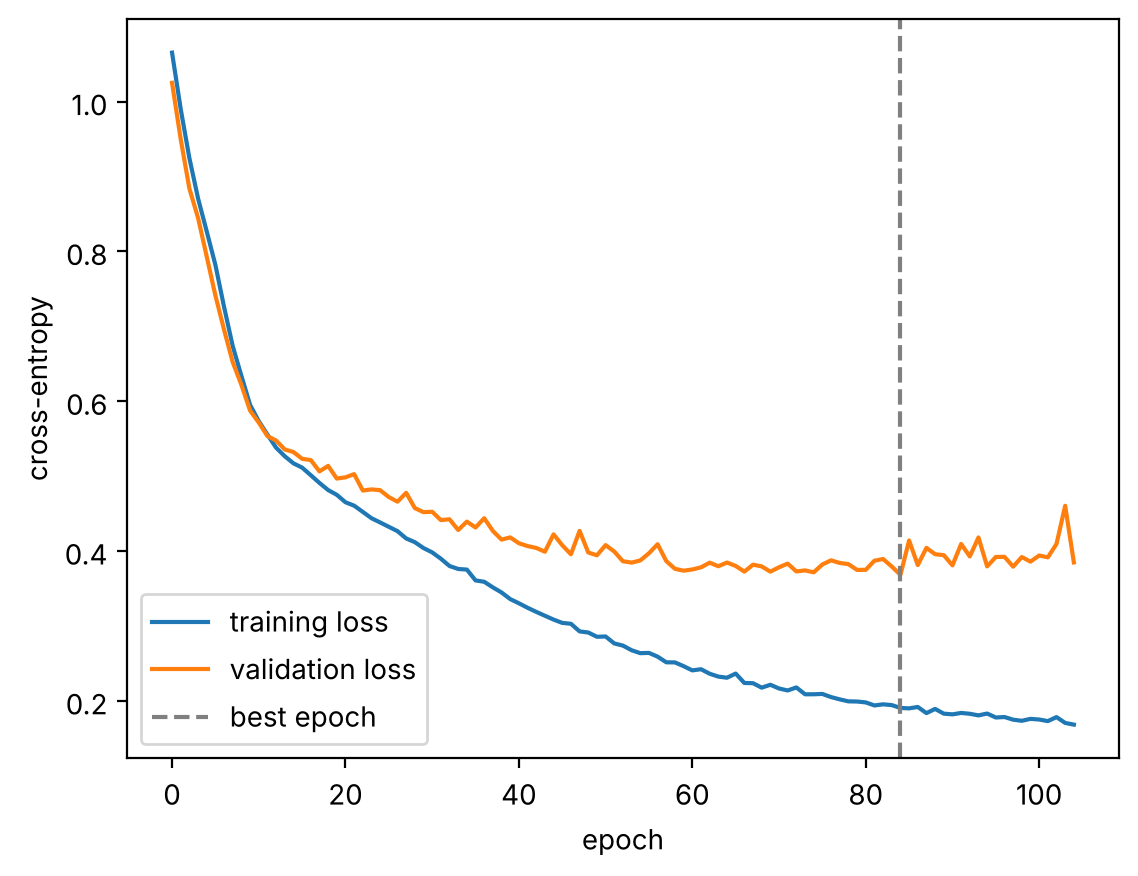

test CE 0.408   test accuracy 0.842   (majority baseline 0.333)
predicted 2   true 2
predicted 2   true 2
predicted 2   true 2
predicted 1   true 1
predicted 2   true 1
predicted 1   true 1
predicted 1   true 1
predicted 0   true 0
predicted 2   true 1
predicted 2   true 2
[[128  15   0]
 [ 11  98  24]
 [  0  13 111]]


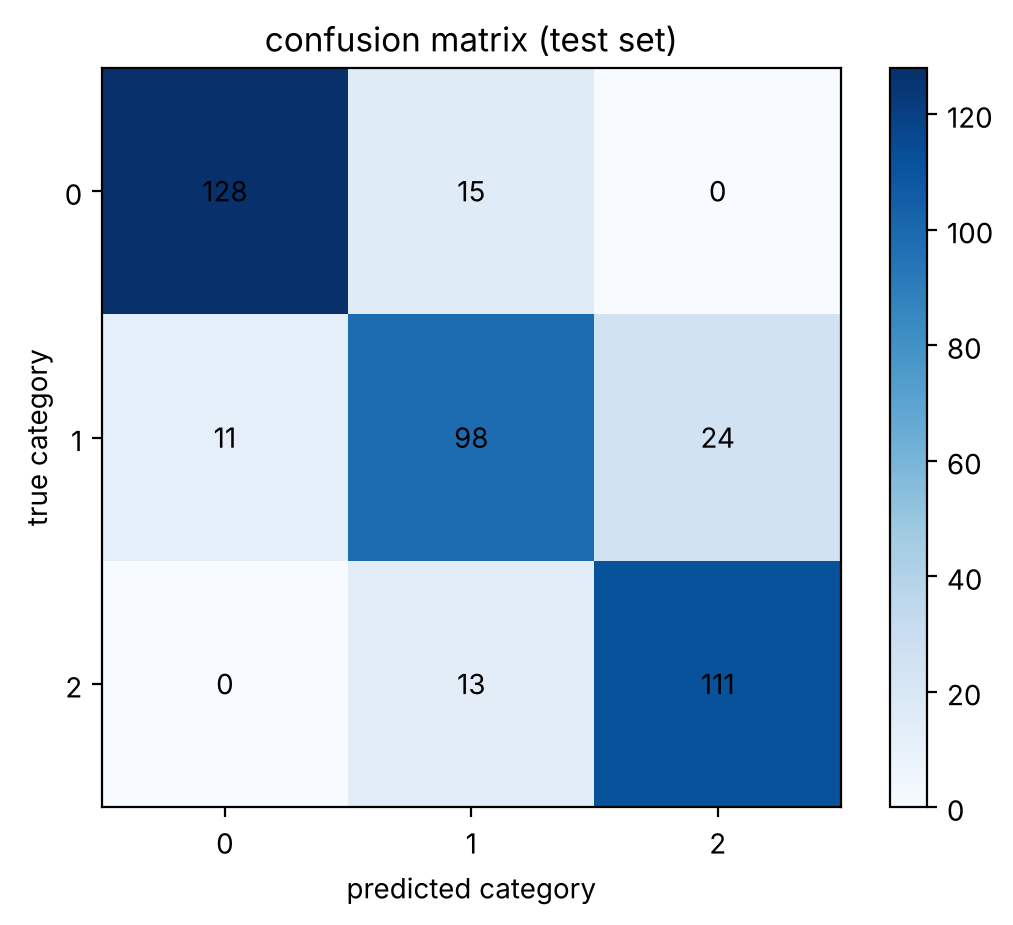

Tester: cl_model_learning OK


True

In [10]:
# implement your solution BELOW

torch.manual_seed(0)
cl_model = ClassificationMLP(X_train.shape[1], 3)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cl_model.parameters(), lr=0.001)

MAX_EPOCHS, PATIENCE = 500, 20
train_losses, val_losses = [], []
best_val_loss, best_epoch, best_state = float("inf"), 0, None
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    cl_model.train()
    batch_losses = []
    for xb, yb in dataloader_cl_train:
        loss = loss_fn(cl_model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    train_losses.append(np.mean(batch_losses))

    cl_model.eval()
    batch_losses = []
    with torch.no_grad():
        for xb, yb in dataloader_cl_val:
            batch_losses.append(loss_fn(cl_model(xb), yb).item())
    val_losses.append(np.mean(batch_losses))

    if val_losses[-1] < best_val_loss:
        best_val_loss, best_epoch = val_losses[-1], epoch
        best_state = copy.deepcopy(cl_model.state_dict())          # a real snapshot
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"early stopping at epoch {epoch}; best epoch {best_epoch}")
            break

cl_model.load_state_dict(best_state)                                # restore, also if the loop ran to the end

plt.plot(train_losses, label="training loss")
plt.plot(val_losses, label="validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label="best epoch")
plt.xlabel("epoch"); plt.ylabel("cross-entropy"); plt.legend(); plt.show()

cl_model.eval()
logits_all, ys_all = [], []
with torch.no_grad():
    for xb, yb in dataloader_cl_test:
        logits_all.append(cl_model(xb)); ys_all.append(yb)
logits_all, ys_all = torch.cat(logits_all), torch.cat(ys_all)

test_ce = loss_fn(logits_all, ys_all).item()
pred_all = logits_all.argmax(dim=1)
test_acc = (pred_all == ys_all).float().mean().item()
print(f"test CE {test_ce:.3f}   test accuracy {test_acc:.3f}   (majority baseline {(yc_test == np.bincount(yc_train).argmax()).mean():.3f})")
for p, t in zip(pred_all[:10], ys_all[:10]):
    print(f"predicted {p.item()}   true {t.item()}")

K = 3
cm = np.bincount(ys_all.numpy() * K + pred_all.numpy(), minlength=K * K).reshape(K, K)
print(cm)
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("predicted category"); plt.ylabel("true category")
plt.xticks(range(K)); plt.yticks(range(K))
for i in range(K):
    for j in range(K):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.title("confusion matrix (test set)")
plt.show()

# implement your solution ABOVE

tester.test('cl_model_learning', test_ce, test_acc)

---
## After the bell

Score yourself honestly:

| | done in time, tester OK | done, needed the docs | needed the solution |
|---|---|---|---|
| A load | | | |
| B split | | | |
| C preprocess | | | |
| D iterators | | | |
| E model | | | |
| F training + plot + test | | | |
| G labels + iterators | | | |
| H model | | | |
| I early stopping + confusion matrix | | | |

For every cell in the right-hand column, go back to the notebook that covers it (A–C → 04, D/G → 05, E/F → 06, H/I → 08 and 09), redo its blank-page drill tomorrow, and repeat this mock in a few days **from an empty copy**.